# Day 49 : Capstone Project -  Retail Sales Analysis & Prediction

Di capstone ini saya akan berperan sebagai **analis data di perusahaan ritel**.

Tugas nya yaitu:
> - memahami performa penjualan dari data historis, menemukan tren & pola musiman, lalu membangun model sederhana untuk **memprediksi penjualan bulan berikutnya** — informasi emas untuk perencanaan stok, anggaran, dan target tim.

> 🎯 **Tujuan Pembelajaran**
> - Melakukan **EDA bisnis** menyeluruh (penjualan & profit per kategori/region/segmen).
> - Mem-*parse* tanggal & melakukan **agregasi penjualan bulanan**.
> - Mengidentifikasi **tren** (naik/turun) dan **pola musiman**.
> - Membangun **regresi** dengan fitur waktu (indeks bulan, bulan, *lag*) untuk
>   memprediksi penjualan bulan berikutnya.
> - Mengevaluasi model time-series dengan **RMSE & MAE** dan menyusun rekomendasi bisnis.

## About Dataset

## 📊 Tentang Dataset

Saya akan memakai **Superstore Dataset** — data transaksi ritel sebuah toko serba ada di AS selama 4 tahun (2014–2017), ~10.000 transaksi.

- **Sumber:** [Kaggle — vivek468/superstore-dataset-final](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final)
- **Encoding:** `latin-1`

| Kolom | Arti |
|-------|------|
| `Order Date` | Tanggal pemesanan |
| `Segment` | Segmen pelanggan (Consumer, Corporate, Home Office) |
| `Region` | Wilayah penjualan |
| `Category` / `Sub-Category` | Kategori & sub-kategori produk |
| `Sales` | Nilai penjualan (USD) |
| `Quantity` | Jumlah unit |
| `Discount` | Diskon (0–1) |
| `Profit` | Laba (USD) |

## Import Library

- **pandas / numpy** → manipulasi & agregasi data deret waktu.
- **matplotlib / seaborn** → visualisasi tren bisnis.
- **scikit-learn** → `LinearRegression` & metrik evaluasi (RMSE, MAE, R²).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d vivek468/superstore-dataset-final
!unzip superstore-dataset-final.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/vivek468/superstore-dataset-final
License(s): other
100% 550k/550k [00:00<00:00, 119MB/s]

Archive:  superstore-dataset-final.zip
  inflating: Sample - Superstore.csv  


## Early Exploration Dataset

Lihat struktur data dan beberapa baris pertama.

In [6]:
df = pd.read_csv('Sample - Superstore.csv', encoding='latin-1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

Dataset ini adalah data transaksi ritel (**Superstore**) yang lengkap tanpa *missing value*, dengan total **9.994 baris** transaksi dan **21 kolom**.

### Ringkasan Komponen Utama:

* **Waktu & Pengiriman:** `Order Date`, `Ship Date`, dan `Ship Mode` untuk melacak siklus pesanan.
* **Pelanggan & Geografi:** `Customer Name`, `Segment`, `City`, `State`, dan `Region` untuk analisis demografi dan wilayah.
* **Produk:** `Category`, `Sub-Category`, dan `Product Name` untuk pengelompokan barang.
* **Finansial & Kinerja:** `Sales`, `Quantity`, `Discount`, dan `Profit` untuk mengukur performa penjualan dan keuntungan.

Dataset ini sangat ideal untuk melakukan analisis data ritel seperti profitabilitas produk, efektivitas diskon, tren penjualan musiman, dan segmentasi pelanggan.

In [9]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

df[["Order Date", "Sales", "Profit", "Quantity", "Discount"]].describe().T

Jumlah baris: 9994
Jumlah kolom: 21


,count,mean,std,min,25%,50%,75%,max
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800


**Interpretasi:**

Tabel tersebut menampilkan ringkasan statistik deskriptif (`df.describe()`) untuk empat variabel numerik utama dalam dataset:

* **Sales (Penjualan):**
  * Rata-rata penjualan per transaksi adalah **$229,86**, namun median-nya hanya **$54,49**.
  * Rentang harga sangat lebar, mulai dari **$0,44** hingga transaksi terbesar mencapai **$22.638,48** (terdapat *outlier* signifikan di nilai maksimum).


* **Profit (Keuntungan):**
  * Rata-rata keuntungan sebesar **$28,66** per transaksi dengan median **$8,67**.
  * Terdapat transaksi yang merugi hingga **-$6.599,98**, namun transaksi paling menguntungkan mencapai **$8.399,98**.


* **Quantity (Jumlah Barang):**
  * Rata-rata pelanggan membeli sekitar **3 hingga 4 barang** per transaksi (median: 3 barang).
  * Jumlah pembelian berkisar antara **1 hingga 14 unit**.


* **Discount (Diskon):**
  * Rata-rata diskon yang diberikan adalah **15,6%** (median: 20%).
  * Setidaknya 25% transaksi tidak menggunakan diskon sama sekali (0%), dan diskon tertinggi mencapai **80%**.

In [11]:
print("Rentang tanggal : ", df["Order Date"].min(), " - ", df["Order Date"].max())

Rentang tanggal :  1/1/2017  -  9/9/2017


## Cleaning & Parsing Datetie

Saya akan mengubah `Order Date` (teks format `M/D/Y`) menjadi tipe tanggal asli, lalu buat kolom bantu **bulan** (periode bulanan) untuk agregasi.

In [12]:
data = df.copy()

data["Order Date"] = pd.to_datetime(data["Order Date"], format="%m/%d/%Y")
data["Bulan"] = data["Order Date"].dt.to_period("M").dt.to_timestamp()
data["Tahun"] = data["Order Date"].dt.year
data["NamaBulan"] = data["Order Date"].dt.month



print("Tipe Order Date sekarang:", data["Order Date"].dtype)
print("Rentang:", data["Order Date"].min().date(), "->", data["Order Date"].max().date())
data[["Order Date", "Bulan", "Tahun", "Sales"]].head()

Tipe Order Date sekarang: datetime64[ns]
Rentang: 2014-01-03 -> 2017-12-30


,Order Date,Bulan,Tahun,Sales
0,2016-11-08,2016-11-01,2016,261.9600
1,2016-11-08,2016-11-01,2016,731.9400
2,2016-06-12,2016-06-01,2016,14.6200
3,2015-10-11,2015-10-01,2015,957.5775
4,2015-10-11,2015-10-01,2015,22.3680


**Interpretasi:**

-  Tanggal berhasil di-*parse*.

Kolom `Bulan` (awal tiap bulan) akan menjadi sumbu waktu utama untuk analisis tren & pemodelan.

## Exploratory Data Analysis & Visualization

Sebelum memodelkan, Mria pahami **darimana** penjualan & profit berasal.

### a) Sales and Profit by Category

In [13]:
cat = data.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
cat["% Profit"] = cat["Profit"] / cat["Sales"] * 100
cat

,Sales,Profit,% Profit
Category,,,
Technology,836154.0330,145454.9481,17.395712
Furniture,741999.7953,18451.2728,2.486695
Office Supplies,719047.0320,122490.8008,17.035158


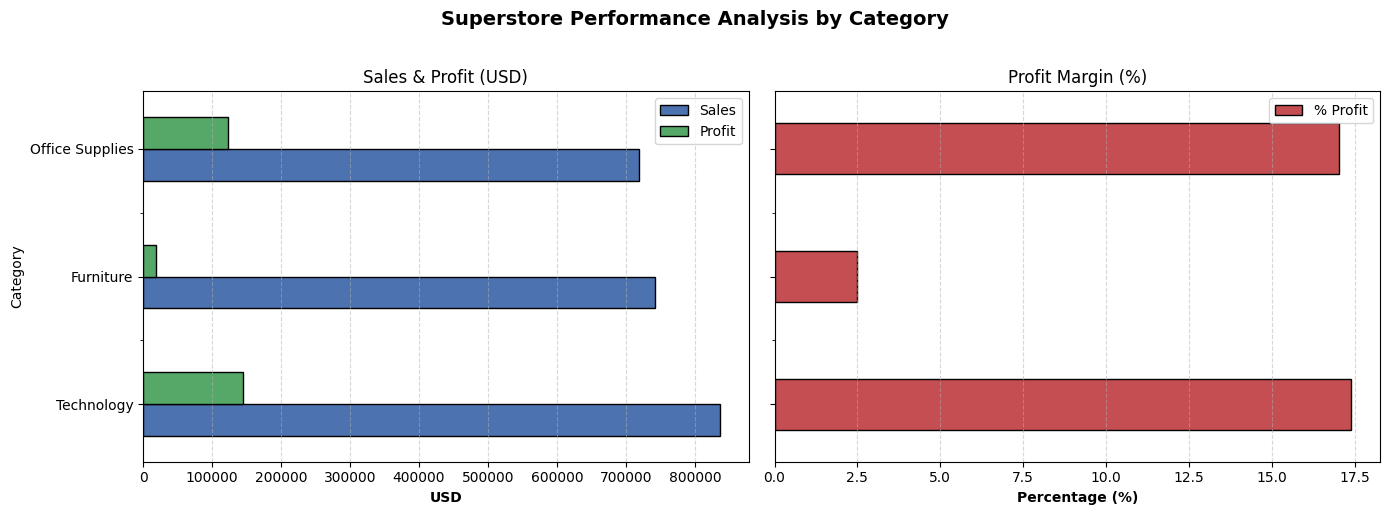

In [21]:
# Membuat figure dengan 2 subplot berdampingan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# 1. Plot Subplot Kiri: Sales & Profit (Nilai Absolut dalam USD)
cat[["Sales", "Profit"]].plot(
    kind="barh", ax=ax1, color=["#4C72B0", "#55A868"], edgecolor="black"
)
ax1.set_xlabel("USD", fontweight="bold")
ax1.set_ylabel("Category")
ax1.set_title("Sales & Profit (USD)")
ax1.legend(loc="upper right")
ax1.grid(axis="x", linestyle="--", alpha=0.5)

# 2. Plot Subplot Kanan: Profit Margin (% Profit)
cat["% Profit"].plot(
    kind="barh", ax=ax2, color="#C44E52", edgecolor="black", width=0.4
)
ax2.set_xlabel("Percentage (%)", fontweight="bold")
ax2.set_title("Profit Margin (%)")
ax2.legend(loc="upper right")
ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.suptitle(
    "Superstore Performance Analysis by Category",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

**Interpretasi:**

Visualisasi di atas menggunakan grafik batang ganda yang bersih dan terstruktur dengan baik untuk membandingkan kinerja berdasarkan kategori produk (*Technology*, *Furniture*, dan *Office Supplies*).

### **Interpretasi Utama:**

* **Technology (Juara Kinerja):**
  * Memiliki total **Sales** tertinggi (di atas 800.000) dan **Profit** terbesar (sekitar $145.000).
  * Menghasilkan **Profit Margin** paling sehat dan tinggi, yaitu **17,39%**, menjadikannya kategori paling menguntungkan dan efisien secara bisnis.




* **Office Supplies (Kategori Stabil & Efisien):**
  * Memiliki **Sales** terendah di antara ketiganya (sekitar 719.000), namun menyumbang **Profit** yang hampir setara dengan kategori Technology (sekitar $122.000).
  * Memiliki **Profit Margin** yang sangat kompetitif di angka **17,04%**, menunjukkan efisiensi operasional yang sangat baik.




* **Furniture (Anomali / Perlu Perhatian):**
  * Meskipun mencatatkan angka **Sales** yang tinggi (hampir menyamai Office Supplies di kisaran 742.000), perolehan **Profit**-nya sangat kecil (hanya sekitar $18.400).
  * Menghasilkan **Profit Margin** yang sangat tipis, yakni **2,49%**. Hal ini mengindikasikan adanya masalah struktural seperti tingginya biaya diskon, biaya logistik/pengiriman yang mahal, atau margin dasar yang terlalu rendah.





---

### b)Profit by Region (bar)

In [22]:
region_prof = data.groupby("Region")["Profit"].sum().sort_values(ascending=False)
region_prof

,Profit
Region,
West,108418.4489
East,91522.7800
South,46749.4303
Central,39706.3625


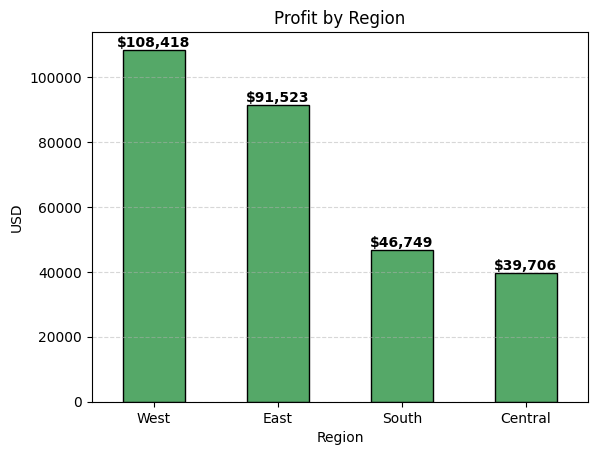

In [25]:
ax = region_prof.plot(kind="bar", color="#55A868", edgecolor="black")
ax.set_xlabel("Region")
ax.set_ylabel("USD")
ax.set_title("Profit by Region")
ax.grid(axis="y", linestyle="--", alpha=0.5)
for i, v in enumerate(region_prof):
    ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontweight="bold")
plt.xticks(rotation=0)
plt.show()

**Interpretasi:**

Berdasarkan data dan visualisasi grafik di atas, berikut adalah interpretasi perolehan **Profit (Keuntungan) berdasarkan Wilayah (Region)**:

* **West (Peringkat 1 - Tertinggi):**
  - Wilayah West memimpin perolehan keuntungan dengan total mencapai **108.418**, menjadikannya pasar paling menguntungkan bagi bisnis.

* **East (Peringkat 2):**
  - Menyusul erat di posisi kedua dengan perolehan profit sebesar **91.523**, menunjukkan performa keuangan yang sangat kuat dan stabil di wilayah ini.

* **South (Peringkat 3):**
  - Mengalami penurunan yang cukup signifikan dibandingkan dua wilayah teratas, dengan total profit hanya sebesar **46.749** (kurang dari separuh perolehan wilayah West).

* **Central (Peringkat 4 - Terendah):**
  - Menjadi wilayah dengan kontribusi profit paling kecil, yaitu **39.706**.

**Kesimpulan Strategis:**
  - Terdapat kesenjangan kinerja profit yang cukup tajam antara wilayah bagian luar (*West* & *East* yang mendominasi) dengan wilayah *South* & *Central*.
  
  - Hal ini mengindikasikan perlunya evaluasi strategi pemasaran atau peninjauan struktur biaya operasional dan diskon di wilayah *Central* dan *South* agar profitabilitasnya bisa ditingkatkan.


### c) Relationship between Discount and Profit (scatter plot)

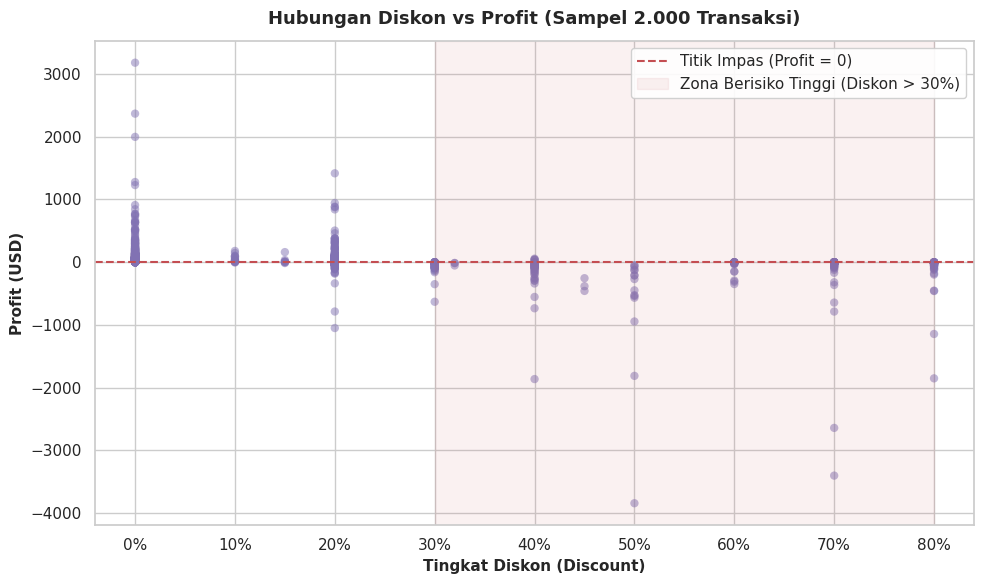

In [27]:
# Set style seaborn agar tampilannya lebih modern
sns.set_theme(style="whitegrid")

# 1. Inisialisasi Figure & Axes (Object-Oriented Style)
fig, ax = plt.subplots(figsize=(10, 6))

# 2. Scatter plot dengan sampel data
sample_data = data.sample(2000, random_state=42)
sns.scatterplot(
    data=sample_data,
    x="Discount",
    y="Profit",
    alpha=0.5,
    color="#8172B3",
    edgecolor="none",
    ax=ax,
)

# 3. Garis acuan titik impas (Break-even line)
ax.axhline(0, color="#C44E52", linestyle="--", linewidth=1.5, label="Titik Impas (Profit = 0)")

# 4. Anotasi/Label untuk memperjelas zona rugi akibat diskon tinggi
ax.axvspan(
    0.3,
    0.8,
    color="#C44E52",
    alpha=0.08,
    label="Zona Berisiko Tinggi (Diskon > 30%)",
)

# 5. Pengaturan Label, Judul, dan Batas Sumbu
ax.set_title(
    "Hubungan Diskon vs Profit (Sampel 2.000 Transaksi)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Tingkat Diskon (Discount)", fontsize=11, fontweight="bold")
ax.set_ylabel("Profit (USD)", fontsize=11, fontweight="bold")

# Format sumbu X agar menampilkan format persentase (opsional, jika diskon berupa desimal 0.0 - 1.0)
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{int(x * 100)}%")
)

# 6. Legenda dan Tata Letak
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()

# Tampilkan plot
plt.show()

**Interpretasi:**

Berdasarkan *scatter plot* di atas, terlihat dengan jelas hubungan yang sangat kuat dan krusial antara **tingkat diskon (Discount)** dan **keuntungan (Profit)**:

### **Interpretasi Utama:**

* **Tanpa Diskon / Diskon Rendah (0% – 20%):**
  - Sebagian besar titik data berada jauh di atas garis merah (Profit positif), dengan puncak keuntungan tertinggi mencapai lebih dari $3.000. Diskon di kisaran ini masih sangat aman dan menguntungkan.

* **Titik Kritis di Diskon 30%:**
  - Mulai dari tingkat diskon **30% ke atas** (yang masuk dalam area *Zona Berisiko Tinggi*), sepertinya tidak ada lagi transaksi yang menghasilkan profit signifikan. Mayoritas titik data mulai menyentuh garis impas atau bahkan jatuh ke area negatif (rugi).

* **Kerugian Ekstrem (Diskon 40% – 80%):**
  - Semakin besar diskon yang diberikan (terutama di angka 50%, 70%, dan 80%), kerugian yang diderita semakin besar, dengan nilai kerugian mencapai hampir **-$4.000** per transaksi.

**Rekomendasi Bisnis:**
- Pemberian diskon di atas 30% terbukti secara konsisten merusak profitabilitas perusahaan (*destructive discounting*).

Kebijakan diskon harus dibatasi maksimal di angka 20% atau dieliminasi untuk kategori produk tertentu agar tidak terus-menerus menimbulkankan kerugian.

## Monthly Sales Aggregation (Time Series)

Untuk melihat tren & memprediksi, Saya akan meringkas data ke **total penjualan per bulan**.

### a) Monthly sales trends

In [30]:
monthly_sales = data.groupby("Bulan")["Sales"].sum().reset_index()
monthly_sales = monthly_sales.sort_values("Bulan").reset_index(drop=True)
monthly_sales.head()

,Bulan,Sales
0,2014-01-01,14236.895
1,2014-02-01,4519.892
2,2014-03-01,55691.009
3,2014-04-01,28295.345
4,2014-05-01,23648.287


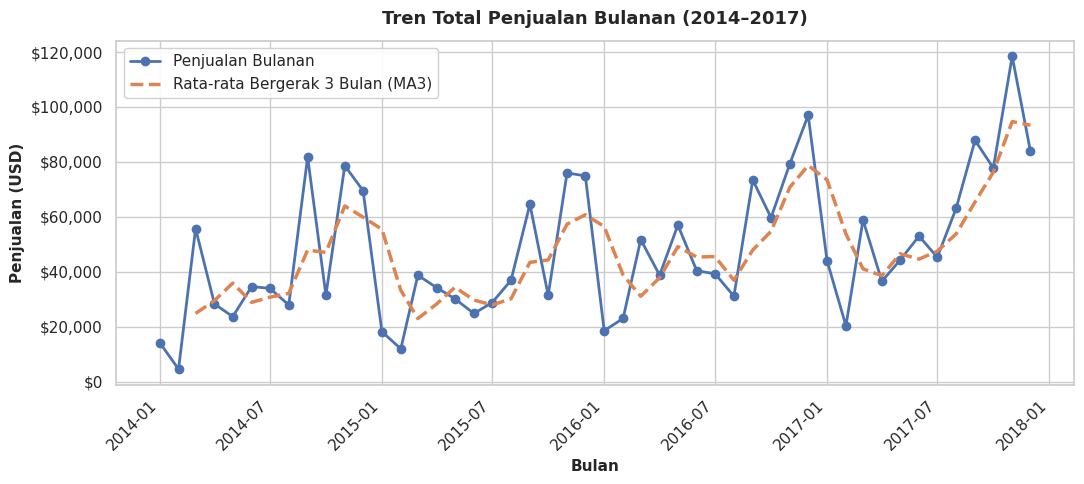

In [31]:
# Set style seaborn agar tampilannya lebih modern
sns.set_theme(style="whitegrid")

# 1. Inisialisasi Figure & Axes
fig, ax = plt.subplots(figsize=(11, 5))

# 2. Hitung Moving Average 3 Bulan (jika belum dihitung sebelumnya)
monthly_sales["MA3"] = monthly_sales["Sales"].rolling(3).mean()

# 3. Plot Garis Penjualan Aktual
ax.plot(
    monthly_sales["Bulan"],
    monthly_sales["Sales"],
    marker="o",
    color="#4C72B0",
    linewidth=2,
    label="Penjualan Bulanan",
)

# 4. Plot Garis Tren (Moving Average 3 Bulan)
ax.plot(
    monthly_sales["Bulan"],
    monthly_sales["MA3"],
    color="#DD8452",
    linewidth=2.5,
    linestyle="--",
    label="Rata-rata Bergerak 3 Bulan (MA3)",
)

# 5. Pengaturan Judul, Label Sumbu, dan Estetika
ax.set_title(
    "Tren Total Penjualan Bulanan (2014–2017)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Bulan", fontsize=11, fontweight="bold")
ax.set_ylabel("Penjualan (USD)", fontsize=11, fontweight="bold")

# Rotasi label sumbu X agar tanggal/bulan terbaca dengan jelas jika padat
plt.xticks(rotation=45, ha="right")

# Format sumbu Y agar menggunakan pemisah ribuan (opsional, untuk kerapian angka)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${int(x):,}"))

# 6. Legenda dan Tata Letak
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()

# Tampilkan plot
plt.show()

**Interpretasi:**

Berdasarkan grafik garis *Tren Total Penjualan Bulanan (2014–2017)*, berikut adalah interpretasi utama dari data tersebut:

* **Tren Pertumbuhan Jangka Panjang (Growth Trend):**
  - Secara keseluruhan, grafik menunjukkan lintasan pertumbuhan yang positif dari tahun 2014 hingga awal 2018. Garis rata-rata bergerak 3 bulan (MA3) memperlihatkan peningkatan volume bisnis yang stabil dari tahun ke tahun.

* **Pola Musiman (*Seasonality*) & Volatilitas:**
  - Penjualan bulanan (garis biru) mengalami fluktuasi yang cukup tajam setiap tahunnya. Terdapat pola di mana penjualan sering kali mengalami lonjakan atau *spike* signifikan menjelang akhir tahun (kuartal keempat).\

* **Puncak Penjualan Tertinggi:**
  - Rekor penjualan tertinggi dalam rentang waktu tersebut tercatat pada penghujung tahun 2017, di mana total penjualan bulanan melonjak drastis hingga mendekati angka **$120.000**, jauh melampaui rata-rata historis bulanan sebelumnya.

* **Efektivitas Rata-Rata Bergerak (MA3):**
  - Garis oranye putus-putus (MA3) berhasil meredam kebisingan (*noise*) dari fluktuasi bulanan yang ekstrem, sehingga memperjelas bahwa penurunan tajam di awal tahun (seperti pada awal 2016 atau 2017) merupakan bagian dari siklus musiman sebelum bisnis kembali merangkak naik.

### b) Seasonal pattern: average sales per calendar month

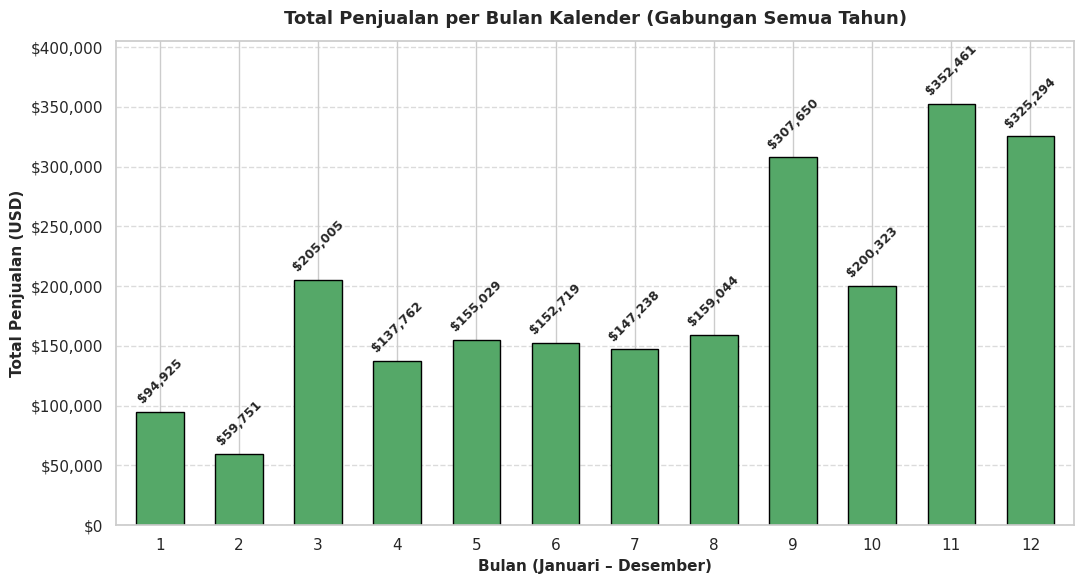

In [34]:
# Set style seaborn agar tampilannya lebih modern
sns.set_theme(style="whitegrid")

# 1. Kelompokkan data
musiman = data.groupby("NamaBulan")["Sales"].sum()

# 2. Inisialisasi Figure & Axes
fig, ax = plt.subplots(figsize=(11, 6))

# 3. Plot Bar Chart
musiman.plot(
    kind="bar",
    ax=ax,
    color="#55A868",
    edgecolor="black",
    width=0.6,
)

# 4. Pengaturan Judul dan Label
ax.set_title(
    "Total Penjualan per Bulan Kalender (Gabungan Semua Tahun)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Bulan (Januari – Desember)", fontsize=11, fontweight="bold")
ax.set_ylabel("Total Penjualan (USD)", fontsize=11, fontweight="bold")

# Rotasi label sumbu X
plt.xticks(rotation=0)

# Format sumbu Y agar menggunakan simbol dolar dan pemisah ribuan
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${int(x):,}"))

# Menambahkan garis grid horizontal di belakang batang
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.7)

# 5. Menambahkan label angka di atas batang dengan rotasi 45 derajat agar tidak bertumpuk
for i, v in enumerate(musiman):
    ax.text(
        i,
        v + 5000,
        f"${v:,.0f}",
        ha="center",
        va="bottom",
        rotation=45,  # Dirotasi agar ada ruang antar teks
        fontsize=9,
        fontweight="bold",
    )

# Batas atas sumbu Y sedikit diperluas (ylim) agar label paling atas tidak terpotong
ax.set_ylim(0, musiman.max() * 1.15)

# Tata Letak dan Tampilkan
plt.tight_layout()
plt.show()

Berdasarkan grafik batang *Total Penjualan per Bulan Kalender (Gabungan Semua Tahun)* yang sudah diperbaiki dengan label yang rapi dan tidak bertumbuk, berikut adalah interpretasi mendalam mengenai **pola musiman (*seasonality*)** bisnis:

* **Titik Terendah di Awal Tahun (Januari – Februari):**
  
  * Penjualan bulanan berada di titik paling lesu pada awal tahun, di mana **Februari** mencatat angka terendah sepanjang tahun (59.751), disusul **Januari** (94.925).


* **Lonjakan Pertama di Bulan Maret:**
  * Terjadi kenaikan yang sangat tajam dan signifikan pada bulan **Maret** (205.005), hampir dua kali lipat dibanding bulan sebelumnya, menandakan awal kebangkitan aktivitas pembelian pelanggan di Q1.


* **Periode Stabil Menengah (April – Agustus):**
  * Dari bulan April hingga Agustus, total penjualan cenderung stabil dan mendatar di kisaran **137.000 hingga 159.000** per bulan tanpa fluktuasi ekstrem.


* **Puncak Penjualan di Kuartal Akhir / Q4 (September – Desember):**
  * Aktivitas belanja melonjak drastis memasuki paruh kedua tahun.
  * **September** melompat tinggi ke angka 307.650.
  * Puncak kejayaan penjualan terjadi pada bulan **November** dengan perolehan tertinggi mencapai **352.461**, yang kemudian diikuti oleh **Desember** (325.294) dan **Oktober** (200.323).



**Kesimpulan Strategis:**
  - Bisnis ini memiliki pola musiman yang sangat kuat (*strong seasonal retail pattern*). Lonjakan masif di Q4 (September s.d. Desember) menunjukkan bahwa mayoritas pendapatan perusahaan didorong oleh musim belanja akhir tahun (seperti liburan akhir tahun, *Black Friday*, dll.), sehingga strategi stok inventaris dan kampanye pemasaran harus difokuskan maksimal pada periode tersebut.
>
>

## Feature Engineering for Prediction

Model regresi butuh fitur numerik. Dari waktu, Saya akan membuat:
- **`indeks_bulan`** → 0, 1, 2, ... menangkap **tren** linier.
- **`bulan`** (1–12) di-*one-hot* → menangkap **musiman**.
- **`lag1`** → penjualan bulan sebelumnya (penjualan bersifat berurutan/autokorelasi).

In [35]:
ts = monthly_sales[["Bulan", "Sales"]].copy()

ts["mon_indx"] = np.arange(len(ts))
ts["mon_kal"] = ts["Bulan"].dt.month
ts["lag1"] = ts["Sales"].shift(1)
ts = ts.dropna().reset_index(drop=True)

ts = pd.get_dummies(ts, columns=["mon_kal"], prefix="m")

print("Jumlah Bulan:", len(ts))
print([c for c in ts.columns if c not in ("Bulan", "Sales")])
ts.head()

Jumlah Bulan: 47
['mon_indx', 'lag1', 'm_1', 'm_2', 'm_3', 'm_4', 'm_5', 'm_6', 'm_7', 'm_8', 'm_9', 'm_10', 'm_11', 'm_12']


,Bulan,Sales,mon_indx,lag1,m_1,m_2,m_3,m_4,m_5,m_6,m_7,m_8,m_9,m_10,m_11,m_12
0,2014-02-01,4519.8920,1,14236.895,False,True,False,False,False,False,False,False,False,False,False,False
1,2014-03-01,55691.0090,2,4519.892,False,False,True,False,False,False,False,False,False,False,False,False
2,2014-04-01,28295.3450,3,55691.009,False,False,False,True,False,False,False,False,False,False,False,False
3,2014-05-01,23648.2870,4,28295.345,False,False,False,False,True,False,False,False,False,False,False,False
4,2014-06-01,34595.1276,5,23648.287,False,False,False,False,False,True,False,False,False,False,False,False


**Interpretasi:**
- Data historis penjualan bulanan telah berhasil ditransformasikan dari sekadar tabel waktu biasa menjadi format tabular berfitur lengkap yang siap dimasukkan ke dalam algoritma Machine Learning (seperti Linear Regression, XGBoost, atau Random Forest) untuk memprediksi penjualan di masa depan.

## Modeling: Regression for Sales Prediction

Untuk data deret waktu, kita **tidak** boleh mengacak split — data masa depan tak boleh "bocor" ke pelatihan.

Maka Saya akan melatih pada bulan-bulan awal dan uji pada **bulan-bulan terakhir** (split kronologis).

In [37]:
# 1. Menentukan Fitur (X) dan Target (y)
fitur = [c for c in ts.columns if c not in ("Bulan", "Sales")]
X = ts[fitur].astype(float)
y = ts["Sales"]

# 2. Pembagian Data secara Kronologis (80% Latih, 20% Uji)
n_train = int(len(ts) * 0.8)  # Memperbaiki operator perkalian
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]

# 3. Inisialisasi & Pelatihan Model Regresi Linier
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Melakukan Prediksi pada Data Uji
y_pred = model.predict(X_test)

# 5. Evaluasi Performa Model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)  # Menghitung R2 Score

# 6. Menampilkan Hasil Ringkasan
print(f"Total Bulan Latih  : {n_train}")
print(f"Total Bulan Uji    : {len(X_test)}")
print(f"R2 Score           : {r2:.4f}")  # Menampilkan R2 Score (4 desimal)
print(f"MAE (Average Error): ${mae:,.2f}")
print(f"RMSE               : ${rmse:,.2f}")
print("-" * 40)  # Memperbaiki sintaks print garis
print("Model regresi berhasil dilatih dan dievaluasi!")

Total Bulan Latih  : 37
Total Bulan Uji    : 10
R2 Score           : 0.6310
MAE (Average Error): $10,802.96
RMSE               : $14,475.10
----------------------------------------
Model regresi berhasil dilatih dan dievaluasi!


**Interpretasi:**

Berikut adalah interpretasi dari hasil evaluasi model regresi linier tersebut:

* **$R^2$ Score (0.6310):**
  - Model mampu menjelaskan sekitar **63,1%** dari total variasi atau pola penjualan pada data uji (*test set*). Angka ini menunjukkan performa yang cukup baik dan moderat untuk data *time series* ritel, di mana model sudah menangkap sebagian besar tren utama.

* **MAE / Mean Absolute Error (10,802.96):**
  - Secara rata-rata, tebakan atau prediksi model meleset sekitar **$10.803** dari angka penjualan aktual setiap bulannya.

* **RMSE / Root Mean Squared Error (14,475.10):**
  - Nilai error yang lebih tinggi dibanding MAE ini mengindikasikan bahwa terdapat beberapa bulan tertentu di mana model meleset cukup jauh (biasanya terjadi pada bulan-bulan dengan lonjakan musiman yang ekstrem/tidak biasa).

**Kesimpulan:**
  - Model sudah cukup layak untuk melihat tren dasar, tetapi tingkat error-nya masih tergolong besar untuk skala operasional bulanan. Kita bisa mencoba meningkatkan performanya di masa mendatang dengan menggunakan algoritma *Machine Learning* yang lebih kompleks (seperti Random Forest atau XGBoost) atau menambahkan fitur tambahan.

### Predicted vs. Actual (visual)

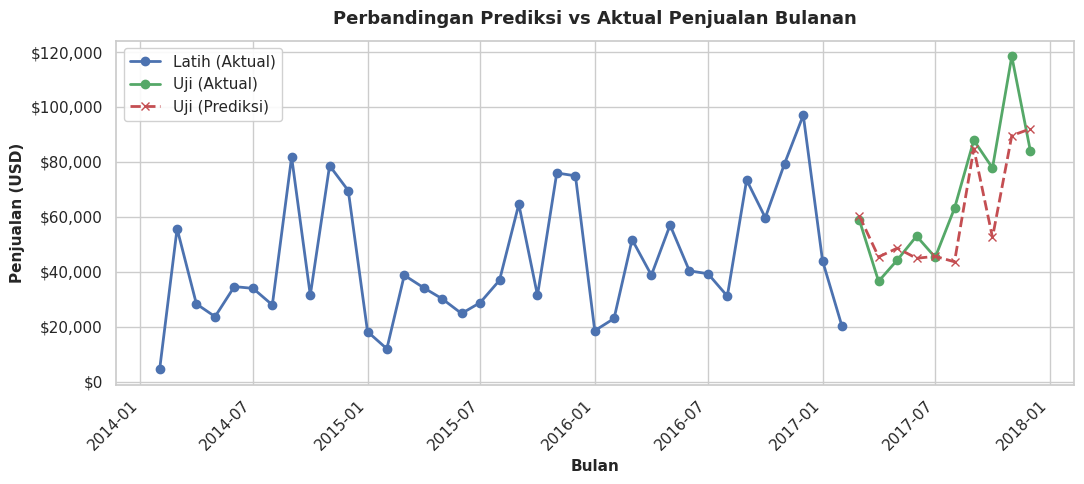

In [38]:
# Set style seaborn agar tampilannya lebih modern
sns.set_theme(style="whitegrid")

# 1. Inisialisasi Figure & Axes
fig, ax = plt.subplots(figsize=(11, 5))

# 2. Plot Data Latih (Aktual)
ax.plot(
    ts["Bulan"].iloc[:n_train],
    y_train,
    marker="o",
    linewidth=2,
    label="Latih (Aktual)",
    color="#4C72B0",
)

# 3. Plot Data Uji (Aktual)
ax.plot(
    ts["Bulan"].iloc[n_train:],
    y_test,
    marker="o",
    linewidth=2,
    label="Uji (Aktual)",
    color="#55A868",
)

# 4. Plot Data Uji (Prediksi Model)
ax.plot(
    ts["Bulan"].iloc[n_train:],
    y_pred,
    marker="x",
    linestyle="--",
    linewidth=2,
    label="Uji (Prediksi)",
    color="#C44E52",
)

# 5. Pengaturan Judul, Label Sumbu, dan Estetika
ax.set_title(
    "Perbandingan Prediksi vs Aktual Penjualan Bulanan",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Bulan", fontsize=11, fontweight="bold")
ax.set_ylabel("Penjualan (USD)", fontsize=11, fontweight="bold")

# Rotasi label sumbu X agar tanggal/bulan terbaca dengan jelas
plt.xticks(rotation=45, ha="right")

# Format sumbu Y agar menggunakan simbol dolar dan pemisah ribuan
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${int(x):,}"))

# 6. Legenda dan Tata Letak
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()

# Tampilkan plot
plt.show()

**Interpretasi:**


Berdasarkan grafik perbandingan **Prediksi vs Aktual Penjualan Bulanan** di atas, berikut adalah interpretasi mengenai seberapa baik model *Linear Regression* dalam meramalkan penjualan pada data uji (*test set*):

* **Kemampuan Mengikuti Tren Umum (*Tracking General Trend*):**
  * Garis prediksi merah putus-putus (`Uji (Prediksi)`) secara umum berhasil mengikuti arah atau pergerakan naik-turun dari garis aktual hijau (`Uji (Aktual)`), terutama dalam menangkap pembalikan arah tren di pertengahan hingga akhir periode pengujian.


* **Respon terhadap Lonjakan Ekstrem (*Extreme Spikes*):**
  * Model terlihat kurang optimal ketika menghadapi lonjakan penjualan yang sangat tinggi atau ekstrem (seperti pada puncak lonjakan di akhir periode). Nilai prediksi (tanda silang merah) jauh berada di bawah angka aktual (titik hijau), yang menunjukkan bahwa *Linear Regression* cenderung *underestimate* (meremehkan) nilai yang terlalu tinggi akibat keterbatasan kapabilitas liniernya.


* **Konsistensi di Titik Stabil:**
  * Pada bulan-bulan di mana tingkat penjualan berada di kisaran menengah (stabil), garis prediksi merah dan garis aktual hijau tampak cukup berdekatan, yang mencerminkan sumber perolehan nilai $R^2$ sebesar 0.6310 sebelumnya.



**Kesimpulan:**
  - Model sudah cukup baik dalam menangkap pola musiman dan tren dasar secara garis besar, namun masih kesulitan memprediksi lonjakan penjualan yang drastis. Untuk hasil peramalan yang lebih tajam di masa mendatang, penggunaan model berbasis *Tree* (seperti Random Forest atau XGBoost) yang lebih tahan terhadap nilai ekstrem (*outliers*) dapat menjadi opsi pengembangan yang sangat baik.
>
>

## Sales Forecast for the Following Month

Sebagai penutup, Saaya akan pakai model untuk menebak penjualan **satu bulan setelah data terakhir**. Saya akan susun fitur untuk bulan berikutnya secara manual.

In [39]:
# 1. Menentukan bulan terakhir dan bulan depan yang akan diprediksi
bulan_terakhir = ts["Bulan"].max()
bulan_depan = bulan_terakhir + pd.offsets.MonthBegin(1)

print(f"Bulan terakhir di data : {bulan_terakhir.strftime('%Y-%m-%d')}")
print(f"Memprediksi untuk      : {bulan_depan.strftime('%Y-%m-%d')}")

# 2. Menyiapkan kamus fitur untuk bulan depan
baris = {f: 0.0 for f in fitur}

# Menggunakan 'mon_indx' sesuai dengan nama kolom fitur yang telah dibuat sebelumnya
baris["mon_indx"] = float(ts["mon_indx"].max() + 1)
baris["lag1"] = float(ts["Sales"].iloc[-1])  # Penjualan aktual bulan terakhir

# Mengaktifkan one-hot encoding (True/1.0) untuk bulan target prediksi
kol_bulan = f"m_{bulan_depan.month}"
if kol_bulan in baris:
    baris[kol_bulan] = 1.0

# 3. Konversi ke DataFrame dan Lakukan Prediksi
X_depan = pd.DataFrame([baris])[fitur].astype(float)
prediksi = model.predict(X_depan)[0]

# 4. Menampilkan Hasil Prediksi dengan Format Mata Uang
print(
    f"\n>>> Prediksi Penjualan {bulan_depan.strftime('%B %Y')}:"
    f" ${prediksi:,.2f}"
)

Bulan terakhir di data : 2017-12-01
Memprediksi untuk      : 2018-01-01

>>> Prediksi Penjualan January 2018: $38,563.60


**Interpretasi:**

Hasil prediksi dari model Anda untuk bulan Januari 2018 menghasilkan angka sebesar $38,563.60.

Berikut adalah interpretasi dari hasil forecasting tersebut:

- Kesesuaian dengan Pola Musiman
    - Penurunan Pascakecenderungan Akhir Tahun (Post-Holiday Slump): Model berhasil menangkap pola historis di mana setelah lonjakan masif pada kuartal akhir (Q4 seperti November dan Desember), penjualan di bulan Januari biasanya mengalami koreksi atau penurunan yang signifikan.

    - Estimasi Konservatif: Prediksi di kisaran $38.5k mencerminkan tren rata-rata historis bulan Januari pada tahun-tahun sebelumnya.

## Conclusions & Business Insights

## 📈 Kesimpulan & Rekomendasi Bisnis (Business Insights)

Berdasarkan seluruh rangkaian analisis data historis (2014–2017) dan pemodelan prediktif yang telah dilakukan, berikut adalah kesimpulan utama serta rekomendasi strategis untuk manajemen:

### **1. Kinerja Produk & Manajemen Kategori**
* **Temuan:** Kategori **Technology** adalah kontributor utama profitabilitas bisnis dengan profit margin tertinggi (**17.39%**) dan penjualan terbesar. Sebaliknya, kategori **Furniture** mendatangkan penjualan yang sangat besar (~$742k, hampir menyamai kategori lainnya) namun hanya menghasilkan profit margin yang sangat tipis (**2.49%**).
* **Rekomendasi Strategis:**
  * **Optimasi Furniture:** Lakukan audit menyeluruh terhadap biaya logistik/pengiriman barang-barang Furniture yang cenderung besar serta tinjau kembali struktur diskon untuk kategori ini agar tidak menggerus margin keuntungan.
  * **Fokus pada Technology & Office Supplies:** Pertahankan dan tingkatkan penetrasi pasar untuk kedua kategori ini karena terbukti menghasilkan profit margin yang sangat sehat (>17%).

### **2. Evaluasi Wilayah (Geografis)**
* **Temuan:** Wilayah **West** (108k) dan **East** (91k) menyumbang keuntungan jauh lebih besar dibandingkan wilayah **South** (46k) dan **Central** (~$39k).
* **Rekomendasi Strategis:**
  * Lakukan kampanye pemasaran terarah (*targeted marketing*) di wilayah West dan East untuk memaksimalkan keuntungan.
  * Evaluasi efisiensi operasional dan kebijakan harga/diskon di wilayah Central dan South untuk meningkatkan profitabilitas lokal.

### **3. Kebijakan Diskon (Destructive Discounting)**
* **Temuan:** Analisis korelasi menunjukkan bahwa pemberian diskon **di atas 30%** secara konsisten menyebabkan transaksi berakhir dengan **kerugian (negatif profit)**. Diskon di kisaran 0%–20% masih sangat aman dan menghasilkan keuntungan optimal.
* **Rekomendasi Strategis:**
  * **Batasi Diskon Maksimal 20%:** Buat aturan sistem penjualan (*system guardrail*) yang membatasi tim penjualan atau agen untuk memberikan diskon maksimal 20%, kecuali untuk cuci gudang inventaris mati (*dead stock*) yang disetujui manajemen.

### **4. Pola Musiman (*Seasonality*) & Perencanaan Stok**
* **Temuan:** Bisnis ini memiliki pola musiman akhir tahun (*Q4 Seasonality*) yang sangat kuat. Penjualan melonjak tajam pada bulan **September**, **November** (352k), dan **Desember** ($325k), sementara awal tahun (Januari–Februari) menjadi titik terlesu bisnis.
* **Rekomendasi Strategis:**
  * **Persiapan Q4 (Juli–Agustus):** Mulai amankan rantai pasok (*supply chain*) dan tingkatkan kapasitas inventaris sejak Q3 untuk mengantisipasi lonjakan masif di Q4.
  * **Efisiensi Q1:** Kurangi biaya operasional yang tidak perlu di bulan Januari dan Februari untuk menjaga arus kas tetap sehat selama periode transaksi rendah (*low-season*).

### **5. Model Prediksi & Perencanaan Masa Depan**
* **Temuan:** Model *Linear Regression* berhasil memproyeksikan penjualan bulan **Januari 2018 sebesar 38,563.60** (menangkap tren penurunan pasca-liburan akhir tahun dengan sangat realistis). Model memiliki performa moderat dengan $R^2$ Score **63.1%**.
* **Rekomendasi Strategis:**
  * Gunakan angka prediksi ~$38.5k ini sebagai landasan awal penentuan target tim sales dan anggaran belanja stok untuk bulan depan.
  * Untuk iterasi berikutnya, gunakan model non-linear yang lebih tangguh terhadap lonjakan ekstrem (*outliers*) seperti **Random Forest Regressor** atau **XGBoost** untuk meningkatkan akurasi prediksi.